# Modelo 2: CNN + LSTM, 2 canales (Fpz-Cz + Pz-Oz), configuración V2

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, accuracy_score, f1_score,
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

TFM_DIR = os.path.expanduser("~/Desktop/TFM/datos_procesados/")
NPZ_PATH = os.path.join(TFM_DIR, "datos_procesados_2canales.npz")
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

print("Cargando datos desde:", NPZ_PATH)

Cargando datos desde: C:\Users\alber/Desktop/TFM/datos_procesados/datos_procesados_2canales.npz


In [2]:
data = np.load(NPZ_PATH)

X_train_norm = data["X_train_norm"]
y_train = data["y_train"]
X_val_norm = data["X_val_norm"]
y_val = data["y_val"]
X_test_norm = data["X_test_norm"]
y_test = data["y_test"]

print("Train:", X_train_norm.shape, "| Val:", X_val_norm.shape, "| Test:", X_test_norm.shape)

Train: (49916, 3000, 2) | Val: (11826, 3000, 2) | Test: (12187, 3000, 2)


## Modelo 2: CNN+LSTM 

In [3]:
def build_cnn_lstm(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(32, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Conv1D(64, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_lstm = build_cnn_lstm(X_train_norm.shape[1:])
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3000, 32)       │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 750, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 187, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,249 (348.63 KB)

 Trainable params: 89,249 (348.63 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento — Configuración V2 (2 canales)

In [4]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    os.path.join(TFM_DIR, "modelo2_cnn_lstm_2canales_v2.keras"),
    monitor="val_loss",
    save_best_only=True,
)

history_lstm = model_lstm.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    class_weight={0: 1.0, 1: (y_train == 0).sum() / max((y_train == 1).sum(), 1)},
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 135s 162ms/step - accuracy: 0.9515 - loss: 0.1370 - val_accuracy: 0.9743 - val_loss: 0.0648
Epoch 2/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 120s 154ms/step - accuracy: 0.9736 - loss: 0.0786 - val_accuracy: 0.9747 - val_loss: 0.0792
Epoch 3/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 122s 156ms/step - accuracy: 0.9764 - loss: 0.0694 - val_accuracy: 0.9642 - val_loss: 0.0806
Epoch 4/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 121s 156ms/step - accuracy: 0.9782 - loss: 0.0653 - val_accuracy: 0.9849 - val_loss: 0.0474
Epoch 5/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 121s 155ms/step - accuracy: 0.9751 - loss: 0.0685 - val_accuracy: 0.9724 - val_loss: 0.0606
Epoch 6/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 121s 155ms/step - accuracy: 0.9793 - loss: 0.0596 - val_accuracy: 0.9796 - val_loss: 0.0561
Epoch 7/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 122s 157ms/step - accuracy: 0.9813 - loss: 0.0554 - val_accuracy: 0.9854 - val_loss: 0.0442
Epoch 8/100
780/780 ━━━━━━━━━━━━━━━━━━━━ 122s 156ms/step - accuracy: 

In [5]:
model_lstm.save(os.path.join(TFM_DIR, "modelo2_cnn_lstm_2canales_v2_final.keras"))

with open(os.path.join(TFM_DIR, "historial_cnn_lstm_2canales_v2.json"), "w") as f:
    json.dump(history_lstm.history, f)

n_epochs_trained = len(history_lstm.history["loss"])
best_epoch = int(np.argmin(history_lstm.history["val_loss"])) + 1
best_val_loss = min(history_lstm.history["val_loss"])

print(f"Modelo e historial guardados. Épocas entrenadas: {n_epochs_trained}")
print(f"Mejor época: {best_epoch} (val_loss = {best_val_loss:.4f})")

Modelo e historial guardados. Épocas entrenadas: 35
Mejor época: 15 (val_loss = 0.0370)


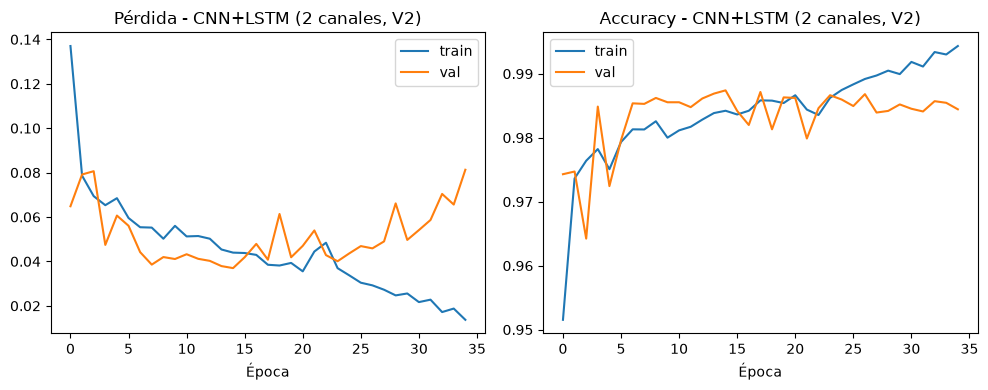

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_lstm.history["loss"], label="train")
plt.plot(history_lstm.history["val_loss"], label="val")
plt.title("Pérdida - CNN+LSTM (2 canales, V2)")
plt.xlabel("Época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history["accuracy"], label="train")
plt.plot(history_lstm.history["val_accuracy"], label="val")
plt.title("Accuracy - CNN+LSTM (2 canales, V2)")
plt.xlabel("Época")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "curvas_entrenamiento_cnn_lstm_2canales_v2.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## Evaluación en el conjunto de test

381/381 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step
              precision    recall  f1-score   support

     Vigilia      0.995     0.959     0.976      6747
       Sueño      0.951     0.994     0.972      5440

    accuracy                          0.974     12187
   macro avg      0.973     0.976     0.974     12187
weighted avg      0.975     0.974     0.974     12187

ROC-AUC: 0.996


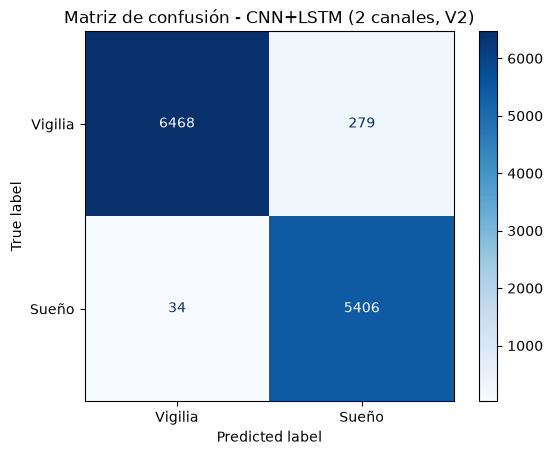

In [7]:
y_pred_prob_lstm = model_lstm.predict(X_test_norm).ravel()
y_pred_lstm = (y_pred_prob_lstm >= 0.5).astype(int)

print(classification_report(y_test, y_pred_lstm, target_names=["Vigilia", "Sueño"], digits=3))

roc_auc_lstm = roc_auc_score(y_test, y_pred_prob_lstm)
print(f"ROC-AUC: {roc_auc_lstm:.3f}")

cm_lstm = confusion_matrix(y_test, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lstm, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - CNN+LSTM (2 canales, V2)")
plt.savefig(os.path.join(IMAGES_DIR, "matriz_confusion_cnn_lstm_2canales_v2.png"),
            dpi=150, bbox_inches="tight")
plt.show()

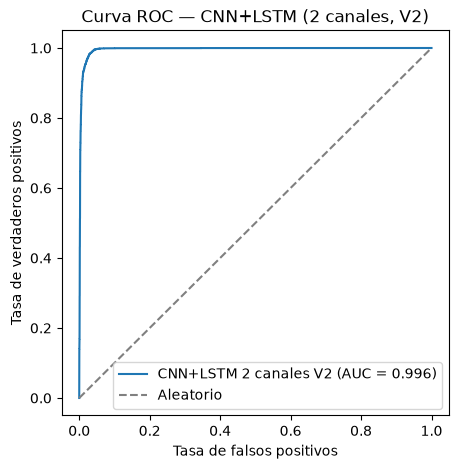

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob_lstm)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"CNN+LSTM 2 canales V2 (AUC = {roc_auc_lstm:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — CNN+LSTM (2 canales, V2)")
plt.legend()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curve_cnn_lstm_2canales_v2.png"),
            dpi=150, bbox_inches="tight")
plt.show()